In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.neighbors import KNeighborsRegressor

from scipy.stats import pearsonr

In [18]:

#load cleaned data
pce_data = pd.read_csv("data/pce_data_clean.csv")
bg_data = pd.read_csv("data/bandgap_data_clean.csv")

print(pce_data.shape, bg_data.shape)   # (635, 19) (588, 10)
pce_data.head()

(635, 19) (588, 10)


,Cs,FA,MA,Pb,Sn,I,Br,Cl,Architecture,ETL,HTL,Substrate,Backcontact,PCE,Voc,Jsc,FF,Eg,Area
0,0.0,0.0,1.0,0.0,1.0,0.00,3.00,0.0,nip,TiO2-c | TiO2-mp,Spiro-MeOTAD,SLG | FTO,Au,3.290000,0.785,9.015000,0.466,2.115000,0.070000
1,0.0,0.0,1.0,0.0,1.0,0.36,2.64,0.0,nip,TiO2-c | TiO2-mp,Spiro-MeOTAD,SLG | FTO,Au,3.030000,0.630,10.280000,0.468,1.830000,0.060000
2,0.0,0.0,1.0,0.0,1.0,1.00,2.00,0.0,nip,TiO2-c | TiO2-mp,PTAA,SLG | FTO,Au,0.510000,0.487,2.240000,0.464,2.130000,0.100000
3,0.0,0.0,1.0,0.0,1.0,1.00,2.00,0.0,nip,TiO2-c | TiO2-mp,Spiro-MeOTAD,SLG | FTO,Au,2.871818,0.450,12.127273,0.507,1.766364,0.086364
4,0.0,0.0,1.0,0.0,1.0,1.50,1.50,0.0,nip,TiO2-c | TiO2-mp,Spiro-MeOTAD,SLG | FTO,Au,2.610000,0.470,17.720000,0.314,1.570000,0.060000


In [19]:
S = ["Cs", "FA", "MA", "Pb", "Sn", "I", "Br", "Cl"]
layer_cols = ["Architecture", "ETL", "HTL", "Substrate", "Backcontact"]

In [20]:
X = pd.get_dummies(pce_data[S + ["Eg", "Area"] + layer_cols], columns=layer_cols, dtype=int)
y = pce_data["PCE"]

Xb = bg_data[S]
yb = bg_data["Eg"]

print(X.shape, Xb.shape)   # (635, 29) (588, 8)

(635, 29) (588, 8)


In [21]:
#splitting the PCE data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(len(X_train), "training rows,", len(X_test), "test rows")   # 508, 127

508 training rows, 127 test rows


In [22]:
#the scoring function for the model
def score(y_true, y_pred):
    r = pearsonr(y_true, y_pred)[0]                  # [0] = the r value ([1] is a p-value)
    rmse = mean_squared_error(y_true, y_pred) ** 0.5  # square root of the mean squared error
    return r, rmse

In [23]:
#linear regression model for PCE
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_pred = lr.predict(X_test)

r, rmse = score(y_test, lr_pred)
print(f"Linear regression:  r = {r:.2f},  RMSE = {rmse:.2f} %")

Linear regression:  r = 0.76,  RMSE = 3.54 %


In [29]:
#ridge regression model for PCE

RR = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50)))
RR.fit(X_train_scaled, y_train)
RR_pred = RR.predict(X_test_scaled)

r, rmse = score(y_test, RR_pred)
print(f"Ridge regression:   r = {r:.2f},  RMSE = {rmse:.2f} %")
print("Chosen alpha:", RR[-1].alpha_)

Ridge regression:   r = 0.76,  RMSE = 3.51 %
Chosen alpha: 8.286427728546842


In [30]:
#KNN regression model for PCE

knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

r, rmse = score(y_test, knn_pred)
print(f"KNN (k=5):  r = {r:.2f},  RMSE = {rmse:.2f} %")   # r = 0.77, RMSE = 3.42 %

KNN (k=5):  r = 0.77,  RMSE = 3.42 %


In [31]:
#band gap model
Xb = bg_data[S]
yb = bg_data["Eg"]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.2, random_state=42)

for name, model in [("Linear", LinearRegression()),
                    ("Ridge", make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 50)))),
                    ("KNN", make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)))]:
    model.fit(Xb_train, yb_train)
    r, rmse = score(yb_test, model.predict(Xb_test))
    print(f"{name:7s} band gap:  r = {r:.2f},  RMSE = {rmse:.3f} eV")

Linear  band gap:  r = 0.93,  RMSE = 0.103 eV
Ridge   band gap:  r = 0.93,  RMSE = 0.103 eV
KNN     band gap:  r = 0.88,  RMSE = 0.127 eV


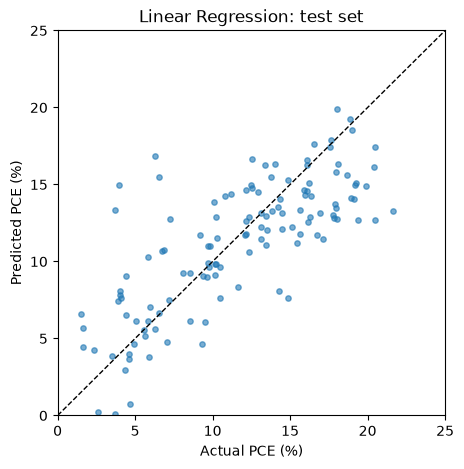

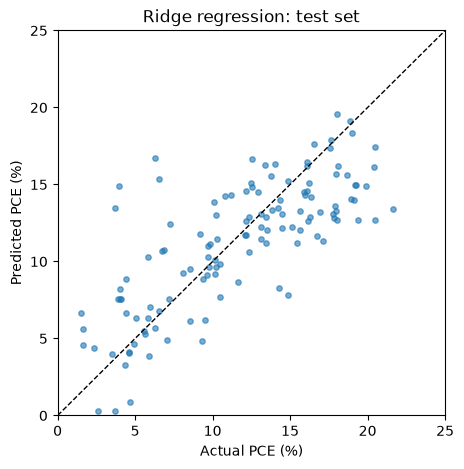

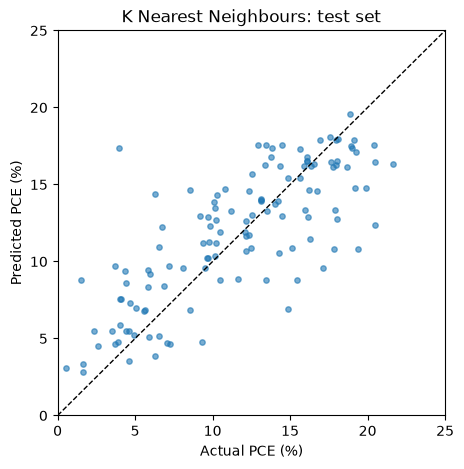

In [34]:
#plotting predicted vs actual values
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, lr_pred, s=15, alpha=0.6)
lims = [0, 25]
ax.plot(lims, lims, "k--", lw=1)        # the y = x line: perfect predictions lie on it
ax.set(xlim=lims, ylim=lims, xlabel="Actual PCE (%)", ylabel="Predicted PCE (%)",
       title="Linear Regression: test set")
plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, RR_pred, s=15, alpha=0.6)
lims = [0, 25]
ax.plot(lims, lims, "k--", lw=1)        # the y = x line: perfect predictions lie on it
ax.set(xlim=lims, ylim=lims, xlabel="Actual PCE (%)", ylabel="Predicted PCE (%)",
       title="Ridge regression: test set")
plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, knn_pred, s=15, alpha=0.6)
lims = [0, 25]
ax.plot(lims, lims, "k--", lw=1)        # the y = x line: perfect predictions lie on it
ax.set(xlim=lims, ylim=lims, xlabel="Actual PCE (%)", ylabel="Predicted PCE (%)",
       title="K Nearest Neighbours: test set")
plt.show()



In [27]:
coefs = pd.Series(lr.coef_, index=X.columns).sort_values()
print(coefs.round(2))

Eg                      -13.01
Sn                       -5.56
HTL_none                 -4.06
Area                     -3.48
ETL_PCBM-60              -1.42
HTL_P3HT                 -1.09
ETL_TiO2-c | TiO2-mp     -0.92
HTL_PEDOT:PSS            -0.88
Backcontact_Al           -0.78
Architecture_nip         -0.76
ETL_PCBM-60 | BCP        -0.42
ETL_TiO2-c               -0.37
I                        -0.16
Substrate_SLG | FTO      -0.00
Cl                       -0.00
Substrate_SLG | ITO       0.00
Br                        0.16
HTL_NiO-c                 0.20
Backcontact_Au            0.31
Backcontact_Ag            0.47
Architecture_pin          0.76
ETL_C60 | BCP             1.45
ETL_SnO2-np               1.68
HTL_PTAA                  2.71
HTL_Spiro-MeOTAD          3.12
Pb                        5.56
MA                      761.64
Cs                      761.80
FA                      764.13
dtype: float64
